# Social Network Analysis

This notebook analyzes reply networks to understand conversation dynamics before, during, and after cancel events.

## Data Source
- Input: `02-preprocessing/outputs/{person}/edges.csv`
- Structure: `source_comment_id` → `target_comment_id` (reply to parent)
- Temporal windows: pre (1-10), cancel (1), post (1-10)

## 1) Configuration
- Select dataset: `mimiminu` or `bodeoum_tv`
- Node type: comment-level (comment_id) or author-level (author_id)
- Edge direction: reply → parent

In [1]:
import os
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from networkx.algorithms.community import louvain_communities
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

BASE_DIR = "/home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis"
OUTPUT_DIR = os.path.join(BASE_DIR, '03-analysis', 'outputs')
FIGURE_DIR = os.path.join(BASE_DIR, '03-analysis', 'figures')
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

PERSON = 'mimiminu'  # or 'bodeoum_tv'
NODE_TYPE = 'author'  # 'comment' or 'author'
USE_WEIGHTS = True

## 2) Data Loading
- Load edges.csv with window/slot metadata
- Load comments.csv for author information (for author-level network)

In [2]:
edges_path = os.path.join(BASE_DIR, '02-preprocessing', 'outputs', PERSON, 'edges.csv')
comments_path = os.path.join(BASE_DIR, '02-preprocessing', 'outputs', PERSON, 'comments.csv')

edges_df = pd.read_csv(edges_path)
comments_df = pd.read_csv(comments_path)

print(f"Edges shape: {edges_df.shape}")
print(f"Comments shape: {comments_df.shape}")
print(f"\nEdges columns: {edges_df.columns.tolist()}")
print(f"\nWindows: {edges_df['window'].unique()}")
print(f"Slots: {edges_df['slot'].unique()}")

Edges shape: (7110, 6)
Comments shape: (16792, 11)

Edges columns: ['source_comment_id', 'target_comment_id', 'author_id', 'video_id', 'window', 'slot']

Windows: <StringArray>
['cancel', 'post', 'pre']
Length: 3, dtype: str
Slots: <StringArray>
['cancel-1',   'post-1',  'post-10',   'post-2',   'post-3',   'post-4',
   'post-5',   'post-6',   'post-7',   'post-8',   'post-9',    'pre-1',
   'pre-10',    'pre-2',    'pre-3',    'pre-4',    'pre-5',    'pre-6',
    'pre-7',    'pre-8',    'pre-9']
Length: 21, dtype: str


## 3) Graph Construction
- Build directed graph (NetworkX DiGraph)
- Apply edge weights for repeated replies
- Build at three levels: full, by window (pre/cancel/post), by slot (pre-1...post-10)

In [3]:
def build_graph(df, node_type='author', use_weights=True):
    if node_type == 'author':
        comment_to_author = comments_df.set_index('comment_id')['author_id'].to_dict()
        df = df.copy()
        df['source'] = df['source_comment_id'].map(comment_to_author)
        df['target'] = df['target_comment_id'].map(comment_to_author)
        df = df.dropna(subset=['source', 'target'])
    else:
        df = df.copy()
        df['source'] = df['source_comment_id']
        df['target'] = df['target_comment_id']
    
    if use_weights:
        edge_weights = df.groupby(['source', 'target']).size().reset_index(name='weight')
        G = nx.DiGraph()
        for _, row in edge_weights.iterrows():
            G.add_edge(row['source'], row['target'], weight=row['weight'])
    else:
        G = nx.from_pandas_edgelist(df, 'source', 'target', create_using=nx.DiGraph())
    
    return G

print("Building full graph...")
G_full = build_graph(edges_df, NODE_TYPE, USE_WEIGHTS)
print(f"Full graph: {G_full.number_of_nodes()} nodes, {G_full.number_of_edges()} edges")

print("\nBuilding graphs by window...")
G_by_window = {}
for window in ['pre', 'cancel', 'post']:
    df_window = edges_df[edges_df['window'] == window]
    G_by_window[window] = build_graph(df_window, NODE_TYPE, USE_WEIGHTS)
    print(f"  {window}: {G_by_window[window].number_of_nodes()} nodes, {G_by_window[window].number_of_edges()} edges")

print("\nBuilding graphs by slot...")
G_by_slot = {}
for slot in sorted(edges_df['slot'].unique()):
    df_slot = edges_df[edges_df['slot'] == slot]
    G_by_slot[slot] = build_graph(df_slot, NODE_TYPE, USE_WEIGHTS)
    print(f"  {slot}: {G_by_slot[slot].number_of_nodes()} nodes, {G_by_slot[slot].number_of_edges()} edges")

Building full graph...


Full graph: 5345 nodes, 6780 edges

Building graphs by window...


  pre: 3093 nodes, 3994 edges
  cancel: 712 nodes, 768 edges
  post: 1875 nodes, 2019 edges

Building graphs by slot...


  cancel-1: 712 nodes, 768 edges
  post-1: 386 nodes, 389 edges
  post-10: 345 nodes, 379 edges
  post-2: 130 nodes, 116 edges
  post-3: 62 nodes, 46 edges
  post-4: 49 nodes, 38 edges


  post-5: 97 nodes, 86 edges
  post-6: 229 nodes, 255 edges
  post-7: 104 nodes, 97 edges
  post-8: 418 nodes, 442 edges
  post-9: 190 nodes, 171 edges
  pre-1: 88 nodes, 87 edges


  pre-10: 236 nodes, 234 edges
  pre-2: 199 nodes, 185 edges
  pre-3: 609 nodes, 652 edges
  pre-4: 371 nodes, 432 edges
  pre-5: 659 nodes, 830 edges


  pre-6: 527 nodes, 616 edges
  pre-7: 553 nodes, 676 edges
  pre-8: 116 nodes, 108 edges
  pre-9: 188 nodes, 178 edges


## 4) Metrics Computation

### Core Metrics
| Metric | Description |
|--------|-------------|
| In-degree | Replies received (authority) |
| Out-degree | Replies sent |
| Weighted in/out | Total reply activity |
| Betweenness centrality | Bridge users |
| PageRank | Influence score |
| Clustering coefficient | Thread formation |
| Density | Network connectivity |
| Connected components | Subgraph structure |

### Polarization Metrics
| Metric | Description |
|--------|-------------|
| Degree variance | Variance of in-degree distribution |
| Degree Gini | Inequality in degree distribution |
| Hub dominance | max_degree / mean_degree |

### Community & Cascade Metrics
| Metric | Description |
|--------|-------------|
| Modularity | Community separation (0=random, 1=highly separated) |
| Num communities | Number of detected conversation clusters |
| Cascade depth | Longest reply chain length |

### Analysis Levels
1. **Full graph** - baseline network properties
2. **Per window** - pre vs cancel vs post comparison
3. **Per slot** - temporal evolution (pre-1...post-10)

In [4]:
def gini_coefficient(values):
    if len(values) == 0 or np.sum(values) == 0:
        return 0
    sorted_values = np.sort(values)
    n = len(values)
    cumsum = np.cumsum(sorted_values)
    return (2 * np.sum((np.arange(1, n + 1) * sorted_values))) / (n * cumsum[-1]) - (n + 1) / n

def compute_cascade_depth(G):
    if G.number_of_nodes() == 0:
        return 0
    try:
        if nx.is_directed_acyclic_graph(G):
            return nx.dag_longest_path_length(G)
        else:
            undirected = G.to_undirected()
            max_depth = 0
            for component in nx.connected_components(undirected):
                subgraph = G.subgraph(component)
                roots = [n for n in subgraph.nodes() if subgraph.in_degree(n) == 0]
                if not roots:
                    roots = [list(component)[0]]
                for root in roots:
                    depths = {root: 1}
                    queue = [root]
                    while queue:
                        node = queue.pop(0)
                        for succ in subgraph.successors(node):
                            if succ not in depths:
                                depths[succ] = depths[node] + 1
                                queue.append(succ)
                                max_depth = max(max_depth, depths[succ])
            return max_depth
    except Exception:
        return 0

def compute_graph_metrics(G, name=''):
    metrics = {'name': name}
    
    metrics['nodes'] = G.number_of_nodes()
    metrics['edges'] = G.number_of_edges()
    metrics['density'] = nx.density(G) if G.number_of_nodes() > 0 else 0
    
    undirected = G.to_undirected()
    metrics['components'] = nx.number_connected_components(undirected)
    
    in_degrees = dict(G.in_degree())
    out_degrees = dict(G.out_degree())
    in_vals = list(in_degrees.values())
    out_vals = list(out_degrees.values())
    
    metrics['in_degree_mean'] = np.mean(in_vals) if in_vals else 0
    metrics['in_degree_max'] = max(in_vals) if in_vals else 0
    metrics['out_degree_mean'] = np.mean(out_vals) if out_vals else 0
    metrics['out_degree_max'] = max(out_vals) if out_vals else 0
    
    if G.number_of_nodes() > 0 and G.number_of_edges() > 0:
        pagerank = nx.pagerank(G)
        metrics['pagerank_mean'] = np.mean(list(pagerank.values()))
        metrics['pagerank_max'] = max(pagerank.values())
        
        betweenness = nx.betweenness_centrality(G)
        metrics['betweenness_mean'] = np.mean(list(betweenness.values()))
        metrics['betweenness_max'] = max(betweenness.values())
        
        undirected = G.to_undirected()
        clustering = nx.clustering(undirected)
        metrics['clustering_mean'] = np.mean(list(clustering.values()))
        metrics['clustering_max'] = max(clustering.values())
        
        metrics['degree_variance'] = np.var(in_vals)
        metrics['degree_gini'] = gini_coefficient(in_vals)
        metrics['hub_dominance'] = metrics['in_degree_max'] / metrics['in_degree_mean'] if metrics['in_degree_mean'] > 0 else 0
        
        communities = list(louvain_communities(undirected))
        metrics['num_communities'] = len(communities)
        metrics['modularity'] = nx.community.modularity(undirected, communities)
        metrics['cascade_depth'] = compute_cascade_depth(G)
    else:
        metrics['pagerank_mean'] = metrics['pagerank_max'] = 0
        metrics['betweenness_mean'] = metrics['betweenness_max'] = 0
        metrics['clustering_mean'] = metrics['clustering_max'] = 0
        metrics['degree_variance'] = metrics['degree_gini'] = metrics['hub_dominance'] = 0
        metrics['num_communities'] = metrics['modularity'] = metrics['cascade_depth'] = 0
    
    return metrics

print("Computing full graph metrics...")
full_metrics = compute_graph_metrics(G_full, 'full')
print(pd.DataFrame([full_metrics]).T)

print("\nComputing per-window metrics...")
window_metrics = []
for window, G in G_by_window.items():
    m = compute_graph_metrics(G, window)
    window_metrics.append(m)
window_df = pd.DataFrame(window_metrics).set_index('name')
print(window_df)

print("\nComputing per-slot metrics...")
slot_metrics = []
for slot, G in G_by_slot.items():
    m = compute_graph_metrics(G, slot)
    slot_metrics.append(m)
slot_df = pd.DataFrame(slot_metrics).set_index('name')
print(slot_df)

Computing full graph metrics...


                          0
name                   full
nodes                  5345
edges                  6780
density            0.000237
components              317
in_degree_mean     1.268475
in_degree_max           103
out_degree_mean    1.268475
out_degree_max           38
pagerank_mean      0.000187
pagerank_max        0.03343
betweenness_mean    0.00003
betweenness_max    0.007099
clustering_mean    0.022634
clustering_max          1.0
degree_variance   13.262439
degree_gini         0.79911
hub_dominance     81.199853
num_communities         365
modularity         0.842083
cascade_depth            23

Computing per-window metrics...


        nodes  edges   density  components  in_degree_mean  in_degree_max  \
name                                                                        
pre      3093   3994  0.000418         163        1.291303             70   
cancel    712    768  0.001517          58        1.078652             70   
post     1875   2019  0.000575         174        1.076800             87   

        out_degree_mean  out_degree_max  pagerank_mean  pagerank_max  \
name                                                                   
pre            1.291303              38       0.000323      0.022513   
cancel         1.078652              28       0.001404      0.036093   
post           1.076800              24       0.000533      0.080788   

        betweenness_mean  betweenness_max  clustering_mean  clustering_max  \
name                                                                         
pre             0.000074         0.013610         0.026532             1.0   
cancel          0.0

          nodes  edges   density  components  in_degree_mean  in_degree_max  \
name                                                                          
cancel-1    712    768  0.001517          58        1.078652             70   
post-1      386    389  0.002618          46        1.007772             30   
post-10     345    379  0.003193          34        1.098551             32   
post-2      130    116  0.006917          28        0.892308             13   
post-3       62     46  0.012163          17        0.741935              7   
post-4       49     38  0.016156          13        0.775510              5   
post-5       97     86  0.009235          21        0.886598             12   
post-6      229    255  0.004884          11        1.113537             18   
post-7      104     97  0.009055          17        0.932692             14   
post-8      418    442  0.002536          33        1.057416             77   
post-9      190    171  0.004762          25        

## 5) Visualization
- Centrality distributions (in-degree, PageRank, betweenness)
- Temporal evolution of key metrics
- Network topology (ego networks, core-periphery)

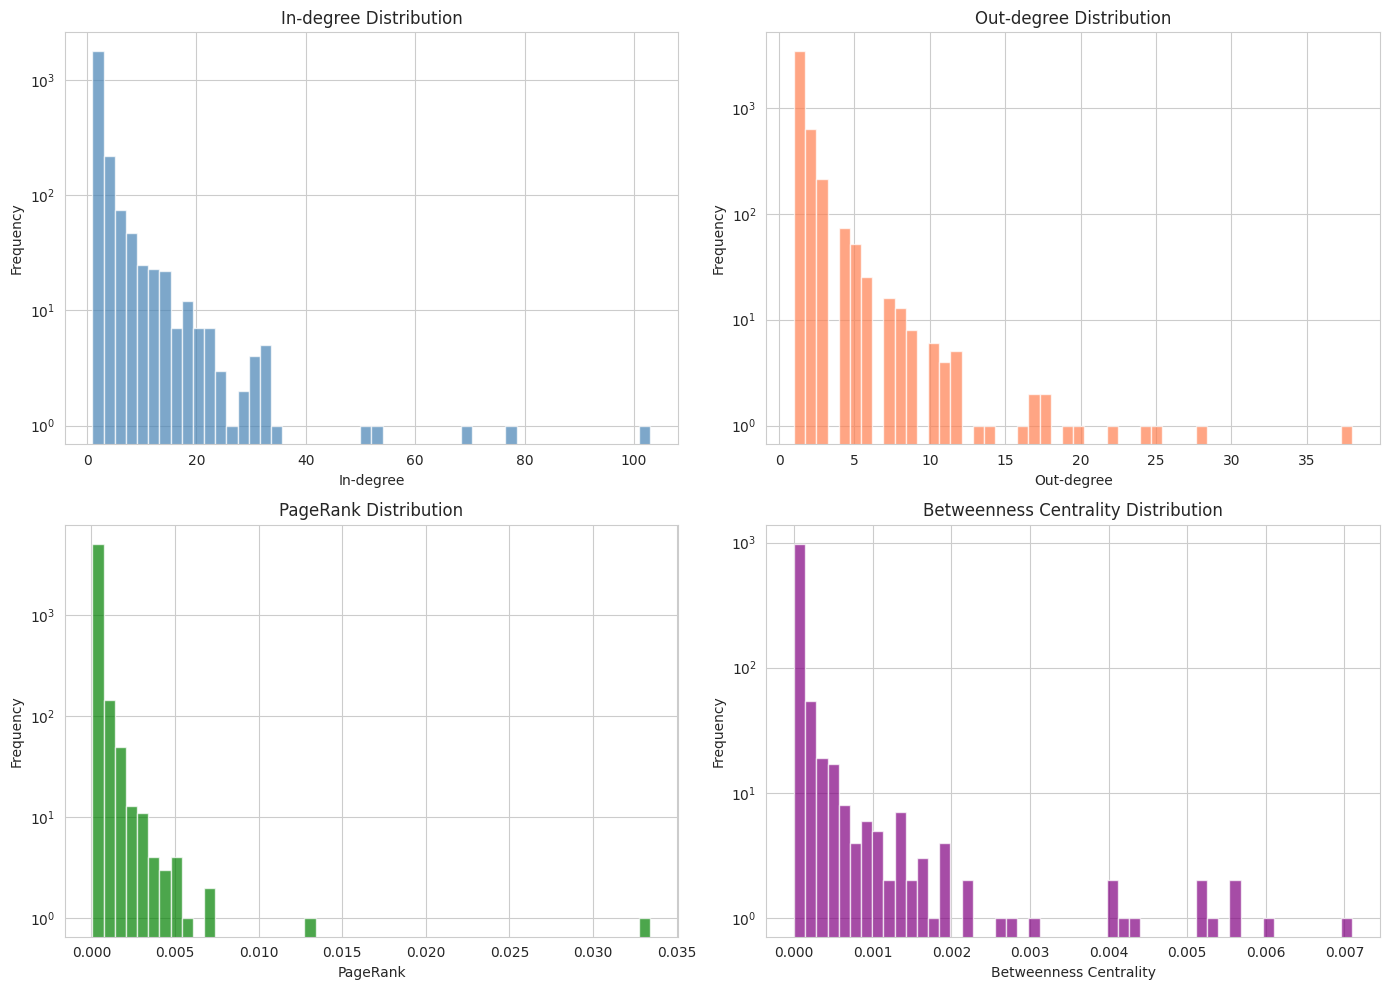

Saved: /home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis/03-analysis/figures/mimiminu_centrality_distributions.png


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

in_degrees = [d for d in dict(G_full.in_degree()).values() if d > 0]
out_degrees = [d for d in dict(G_full.out_degree()).values() if d > 0]

axes[0, 0].hist(in_degrees, bins=50, color='steelblue', alpha=0.7)
axes[0, 0].set_xlabel('In-degree')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('In-degree Distribution')
axes[0, 0].set_yscale('log')

axes[0, 1].hist(out_degrees, bins=50, color='coral', alpha=0.7)
axes[0, 1].set_xlabel('Out-degree')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Out-degree Distribution')
axes[0, 1].set_yscale('log')

if G_full.number_of_nodes() > 0:
    pagerank = nx.pagerank(G_full)
    pr_values = list(pagerank.values())
    axes[1, 0].hist(pr_values, bins=50, color='green', alpha=0.7)
    axes[1, 0].set_xlabel('PageRank')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].set_title('PageRank Distribution')
    axes[1, 0].set_yscale('log')

    betweenness = nx.betweenness_centrality(G_full)
    bw_values = [v for v in betweenness.values() if v > 0]
    if bw_values:
        axes[1, 1].hist(bw_values, bins=50, color='purple', alpha=0.7)
    axes[1, 1].set_xlabel('Betweenness Centrality')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].set_title('Betweenness Centrality Distribution')
    axes[1, 1].set_yscale('log')

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, f'{PERSON}_centrality_distributions.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURE_DIR}/{PERSON}_centrality_distributions.png")

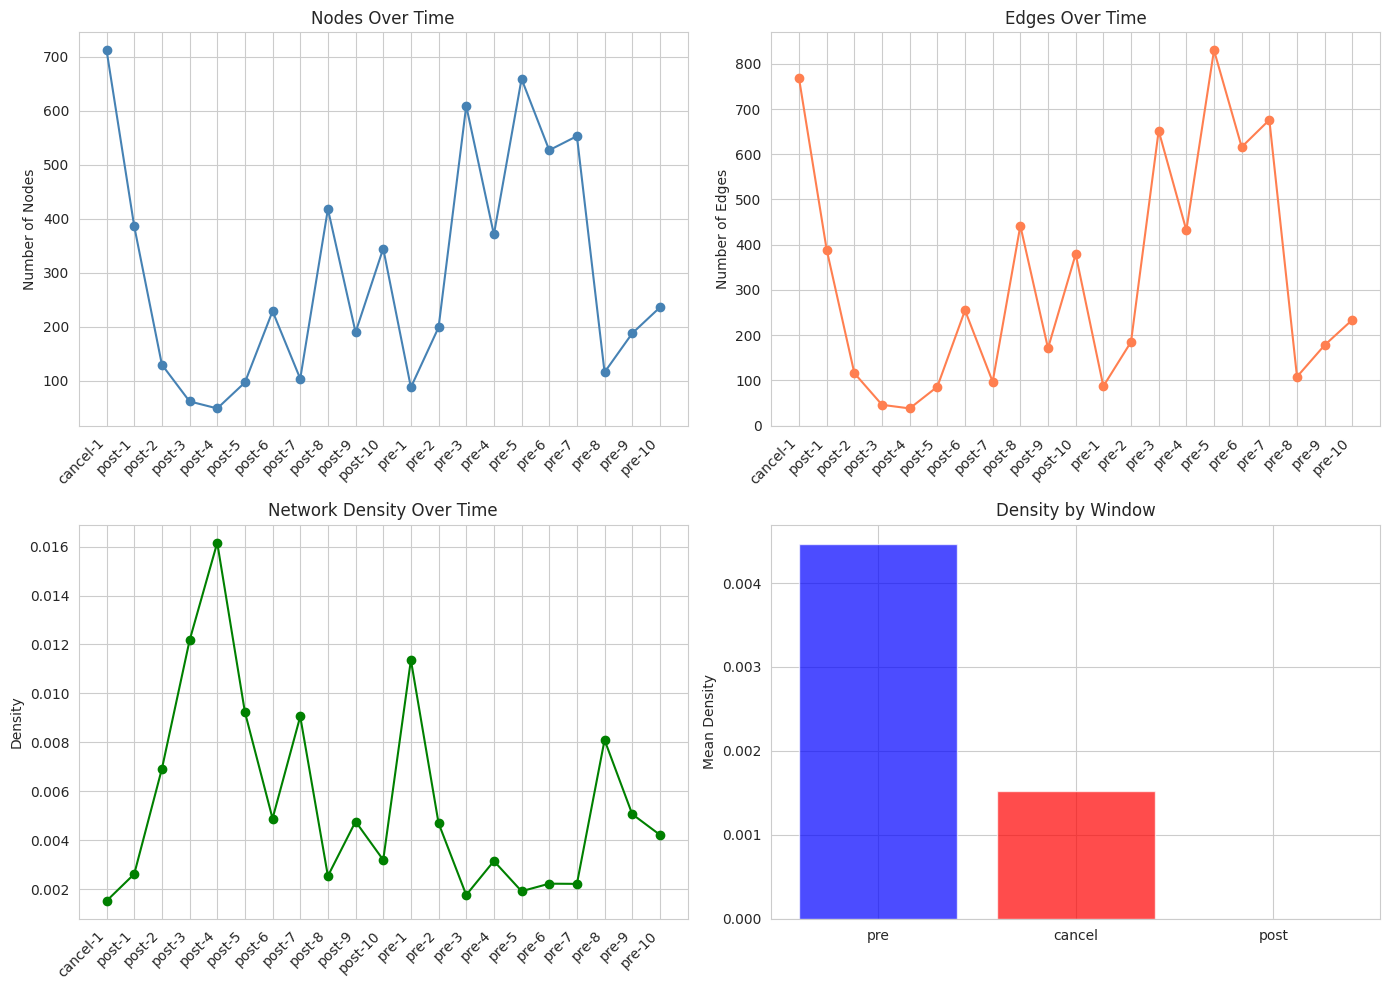

Saved: /home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis/03-analysis/figures/mimiminu_temporal_evolution.png


In [6]:
slot_order = sorted(G_by_slot.keys(), key=lambda x: (x.split('-')[0], int(x.split('-')[1]) if '-' in x else 0))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

x_labels = slot_order
x_pos = range(len(slot_order))

nodes_over_time = [G_by_slot[s].number_of_nodes() for s in slot_order]
edges_over_time = [G_by_slot[s].number_of_edges() for s in slot_order]
density_over_time = [nx.density(G_by_slot[s]) if G_by_slot[s].number_of_nodes() > 0 else 0 for s in slot_order]

axes[0, 0].plot(x_pos, nodes_over_time, marker='o', color='steelblue')
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(x_labels, rotation=45, ha='right')
axes[0, 0].set_ylabel('Number of Nodes')
axes[0, 0].set_title('Nodes Over Time')

axes[0, 1].plot(x_pos, edges_over_time, marker='o', color='coral')
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(x_labels, rotation=45, ha='right')
axes[0, 1].set_ylabel('Number of Edges')
axes[0, 1].set_title('Edges Over Time')

axes[1, 0].plot(x_pos, density_over_time, marker='o', color='green')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(x_labels, rotation=45, ha='right')
axes[1, 0].set_ylabel('Density')
axes[1, 0].set_title('Network Density Over Time')

window_groups = {'pre': list(range(1, 11)), 'cancel': [11], 'post': list(range(12, 22))}
window_means = []
for window in ['pre', 'cancel', 'post']:
    idx = window_groups[window]
    if window == 'pre':
        slots = [f'pre-{i}' for i in idx]
    elif window == 'cancel':
        slots = ['cancel-1']
    else:
        slots = [f'post-{i}' for i in idx]
    vals = [nx.density(G_by_slot[s]) if s in G_by_slot and G_by_slot[s].number_of_nodes() > 0 else 0 for s in slots]
    window_means.append(np.mean(vals))

axes[1, 1].bar(['pre', 'cancel', 'post'], window_means, color=['blue', 'red', 'green'], alpha=0.7)
axes[1, 1].set_ylabel('Mean Density')
axes[1, 1].set_title('Density by Window')

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, f'{PERSON}_temporal_evolution.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURE_DIR}/{PERSON}_temporal_evolution.png")

In [7]:
print("Top 10 nodes by in-degree (most replied to):")
in_deg = dict(G_full.in_degree())
top_in = sorted(in_deg.items(), key=lambda x: x[1], reverse=True)[:10]
top_in_df = pd.DataFrame(top_in, columns=['node', 'in_degree'])
if NODE_TYPE == 'author':
    id_to_name = comments_df.drop_duplicates('author_id').set_index('author_id')['author'].to_dict()
    top_in_df['name'] = top_in_df['node'].map(id_to_name)
    print(top_in_df[['name', 'in_degree']].to_string(index=False))
else:
    print(top_in_df.to_string(index=False))

print("\nTop 10 nodes by out-degree (most active replies):")
out_deg = dict(G_full.out_degree())
top_out = sorted(out_deg.items(), key=lambda x: x[1], reverse=True)[:10]
top_out_df = pd.DataFrame(top_out, columns=['node', 'out_degree'])
if NODE_TYPE == 'author':
    top_out_df['name'] = top_out_df['node'].map(id_to_name)
    print(top_out_df[['name', 'out_degree']].to_string(index=False))
else:
    print(top_out_df.to_string(index=False))

Top 10 nodes by in-degree (most replied to):
              name  in_degree
@mimiminu_official        103
          @SUN-w7b         77
       @Hyun-zo1ww         70
  @user-pi7qi8el3j         53
      @jack_endrew         50
          @사랑한다민철아         34
          @istj285         33
            @하-h6f         33
      @trossard_06         32
          @08_dhdh         32

Top 10 nodes by out-degree (most active replies):
            name  out_degree
@user-pi7qi8el3j          38
         @rucyjw          28
       @liverlyz          25
           @생강국어          24
 @Iiilliililiili          22
      @이승우-m5n5s          20
       @안녕하지않으세요          19
     @행복을찾아서-p1f          18
        @5코3성강민철          18
          @케빈단소4          17


## 5.2) Network Structure Analysis

### Heatmap: Metrics by Window
Normalized comparison of network properties across pre/cancel/post periods.

### Polarization Metrics
- **Degree variance**: Inequalities in who receives replies
- **Degree Gini**: Formal inequality measure (0=equal, 1=maximum inequality)
- **Hub dominance**: How much one node dominates vs average

### Amplification Analysis
- **Edge amplification**: cancel_edges / pre_edges
- **Density amplification**: cancel_density / pre_density
- **Node amplification**: cancel_nodes / pre_nodes

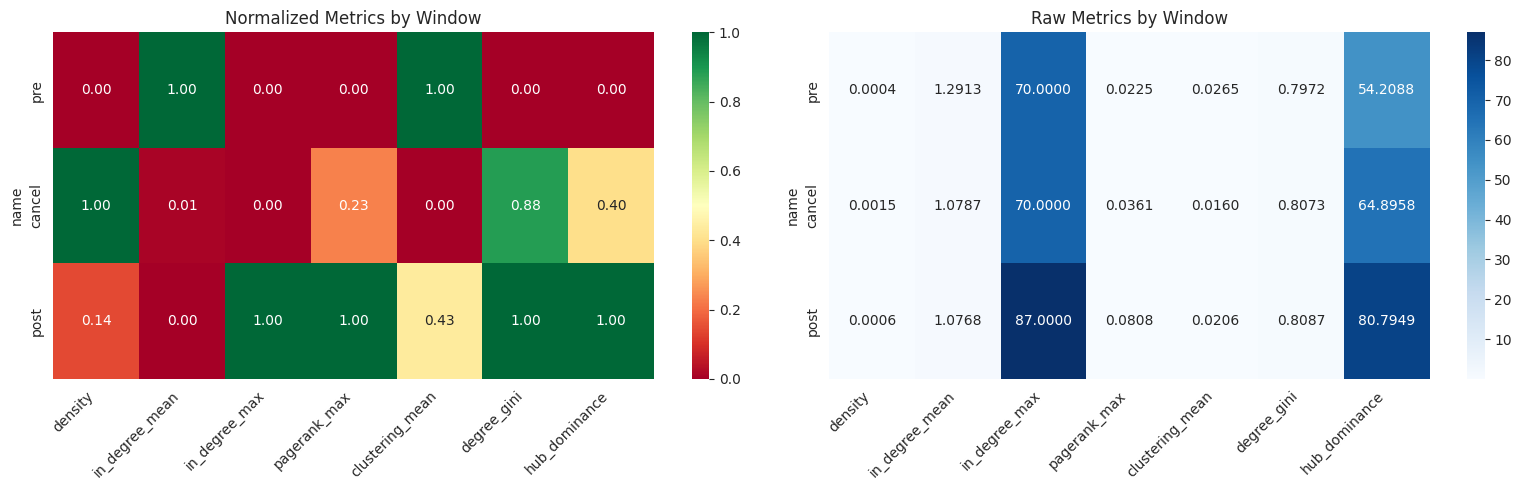

Saved: /home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis/03-analysis/figures/mimiminu_metrics_heatmap.png


In [8]:
metrics_for_heatmap = ['density', 'in_degree_mean', 'in_degree_max', 'pagerank_max', 'clustering_mean', 'degree_gini', 'hub_dominance']

heatmap_data = window_df[metrics_for_heatmap].copy()

heatmap_normalized = heatmap_data.copy()
for col in heatmap_data.columns:
    col_min = heatmap_data[col].min()
    col_max = heatmap_data[col].max()
    if col_max - col_min > 0:
        heatmap_normalized[col] = (heatmap_data[col] - col_min) / (col_max - col_min)
    else:
        heatmap_normalized[col] = 0

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(heatmap_normalized, annot=True, fmt='.2f', cmap='RdYlGn', 
            xticklabels=metrics_for_heatmap, yticklabels=heatmap_normalized.index,
            ax=axes[0])
axes[0].set_title('Normalized Metrics by Window')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

sns.heatmap(heatmap_data, annot=True, fmt='.4f', cmap='Blues',
            xticklabels=metrics_for_heatmap, yticklabels=heatmap_data.index,
            ax=axes[1])
axes[1].set_title('Raw Metrics by Window')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, f'{PERSON}_metrics_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURE_DIR}/{PERSON}_metrics_heatmap.png")


=== Polarization Metrics by Window ===
        degree_variance  degree_gini  hub_dominance
name                                               
pre           11.822999     0.797238      54.208813
cancel        11.196061     0.807321      64.895833
post          10.690635     0.808654      80.794948


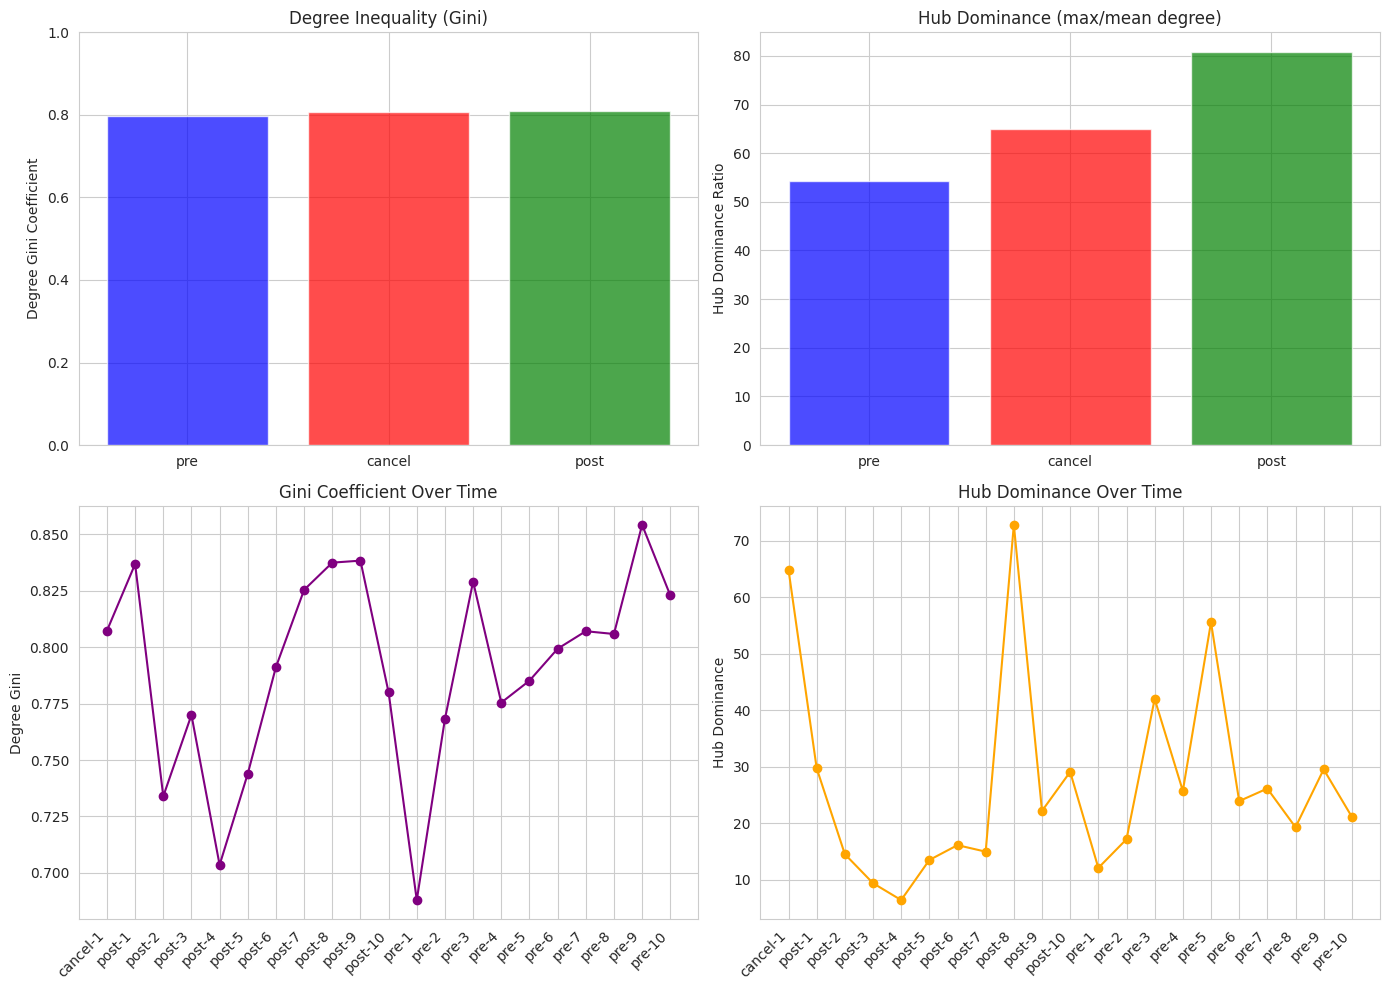

Saved: /home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis/03-analysis/figures/mimiminu_polarization_analysis.png


In [9]:
print("\n=== Polarization Metrics by Window ===")
print(window_df[['degree_variance', 'degree_gini', 'hub_dominance']])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

windows = ['pre', 'cancel', 'post']
colors = {'pre': 'blue', 'cancel': 'red', 'post': 'green'}

degree_gini_vals = [window_df.loc[w, 'degree_gini'] for w in windows]
axes[0, 0].bar(windows, degree_gini_vals, color=[colors[w] for w in windows], alpha=0.7)
axes[0, 0].set_ylabel('Degree Gini Coefficient')
axes[0, 0].set_title('Degree Inequality (Gini)')
axes[0, 0].set_ylim(0, 1)

hub_dom_vals = [window_df.loc[w, 'hub_dominance'] for w in windows]
axes[0, 1].bar(windows, hub_dom_vals, color=[colors[w] for w in windows], alpha=0.7)
axes[0, 1].set_ylabel('Hub Dominance Ratio')
axes[0, 1].set_title('Hub Dominance (max/mean degree)')

gini_over_time = [slot_df.loc[s, 'degree_gini'] if s in slot_df.index else 0 for s in slot_order]
axes[1, 0].plot(x_pos, gini_over_time, marker='o', color='purple')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(x_labels, rotation=45, ha='right')
axes[1, 0].set_ylabel('Degree Gini')
axes[1, 0].set_title('Gini Coefficient Over Time')

hub_over_time = [slot_df.loc[s, 'hub_dominance'] if s in slot_df.index else 0 for s in slot_order]
axes[1, 1].plot(x_pos, hub_over_time, marker='o', color='orange')
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(x_labels, rotation=45, ha='right')
axes[1, 1].set_ylabel('Hub Dominance')
axes[1, 1].set_title('Hub Dominance Over Time')

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, f'{PERSON}_polarization_analysis.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURE_DIR}/{PERSON}_polarization_analysis.png")


=== Amplification Analysis (Cancel vs Pre) ===
Edge amplification: 0.192x
Density amplification: 3.633x
Node amplification: 0.230x
Gini amplification: 1.013x


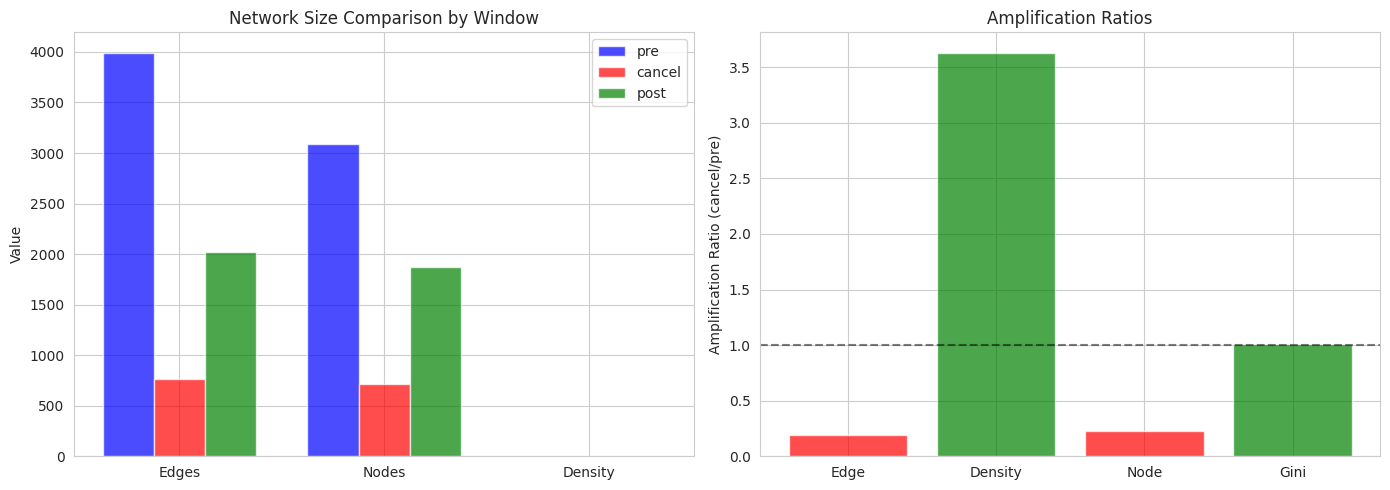

Saved: /home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis/03-analysis/figures/mimiminu_amplification.png


In [10]:
pre_metrics = window_df.loc['pre']
cancel_metrics = window_df.loc['cancel']
post_metrics = window_df.loc['post']

edge_amplification = cancel_metrics['edges'] / pre_metrics['edges'] if pre_metrics['edges'] > 0 else 0
density_amplification = cancel_metrics['density'] / pre_metrics['density'] if pre_metrics['density'] > 0 else 0
node_amplification = cancel_metrics['nodes'] / pre_metrics['nodes'] if pre_metrics['nodes'] > 0 else 0
gini_amplification = cancel_metrics['degree_gini'] / pre_metrics['degree_gini'] if pre_metrics['degree_gini'] > 0 else 0

print("\n=== Amplification Analysis (Cancel vs Pre) ===")
print(f"Edge amplification: {edge_amplification:.3f}x")
print(f"Density amplification: {density_amplification:.3f}x")
print(f"Node amplification: {node_amplification:.3f}x")
print(f"Gini amplification: {gini_amplification:.3f}x")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metrics_compare = ['edges', 'nodes', 'density']
pre_vals = [pre_metrics[m] for m in metrics_compare]
cancel_vals = [cancel_metrics[m] for m in metrics_compare]
post_vals = [post_metrics[m] for m in metrics_compare]

x = np.arange(len(metrics_compare))
width = 0.25

axes[0].bar(x - width, pre_vals, width, label='pre', color='blue', alpha=0.7)
axes[0].bar(x, cancel_vals, width, label='cancel', color='red', alpha=0.7)
axes[0].bar(x + width, post_vals, width, label='post', color='green', alpha=0.7)
axes[0].set_xticks(x)
axes[0].set_xticklabels(['Edges', 'Nodes', 'Density'])
axes[0].legend()
axes[0].set_title('Network Size Comparison by Window')
axes[0].set_ylabel('Value')

amp_metrics = ['Edge', 'Density', 'Node', 'Gini']
amp_vals = [edge_amplification, density_amplification, node_amplification, gini_amplification]
amp_colors = ['green' if v > 1 else 'red' for v in amp_vals]

axes[1].bar(amp_metrics, amp_vals, color=amp_colors, alpha=0.7)
axes[1].axhline(y=1, color='black', linestyle='--', alpha=0.5)
axes[1].set_ylabel('Amplification Ratio (cancel/pre)')
axes[1].set_title('Amplification Ratios')

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, f'{PERSON}_amplification.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURE_DIR}/{PERSON}_amplification.png")

## 5.3) Community & Cascade Analysis

### Modularity (Community Structure)
- Louvain community detection on undirected graphs
- Higher modularity = more distinct communities
- Compare across pre/cancel/post

### Cascade Depth (Conversation Length)
- Longest path in directed acyclic graph
- Measures how deep reply chains go
- Deeper during cancel = longer engagement chains


=== Community & Cascade Metrics by Window ===
        num_communities  modularity  cascade_depth
name                                              
pre                 202    0.833347             20
cancel               76    0.873762              7
post                205    0.909890             10


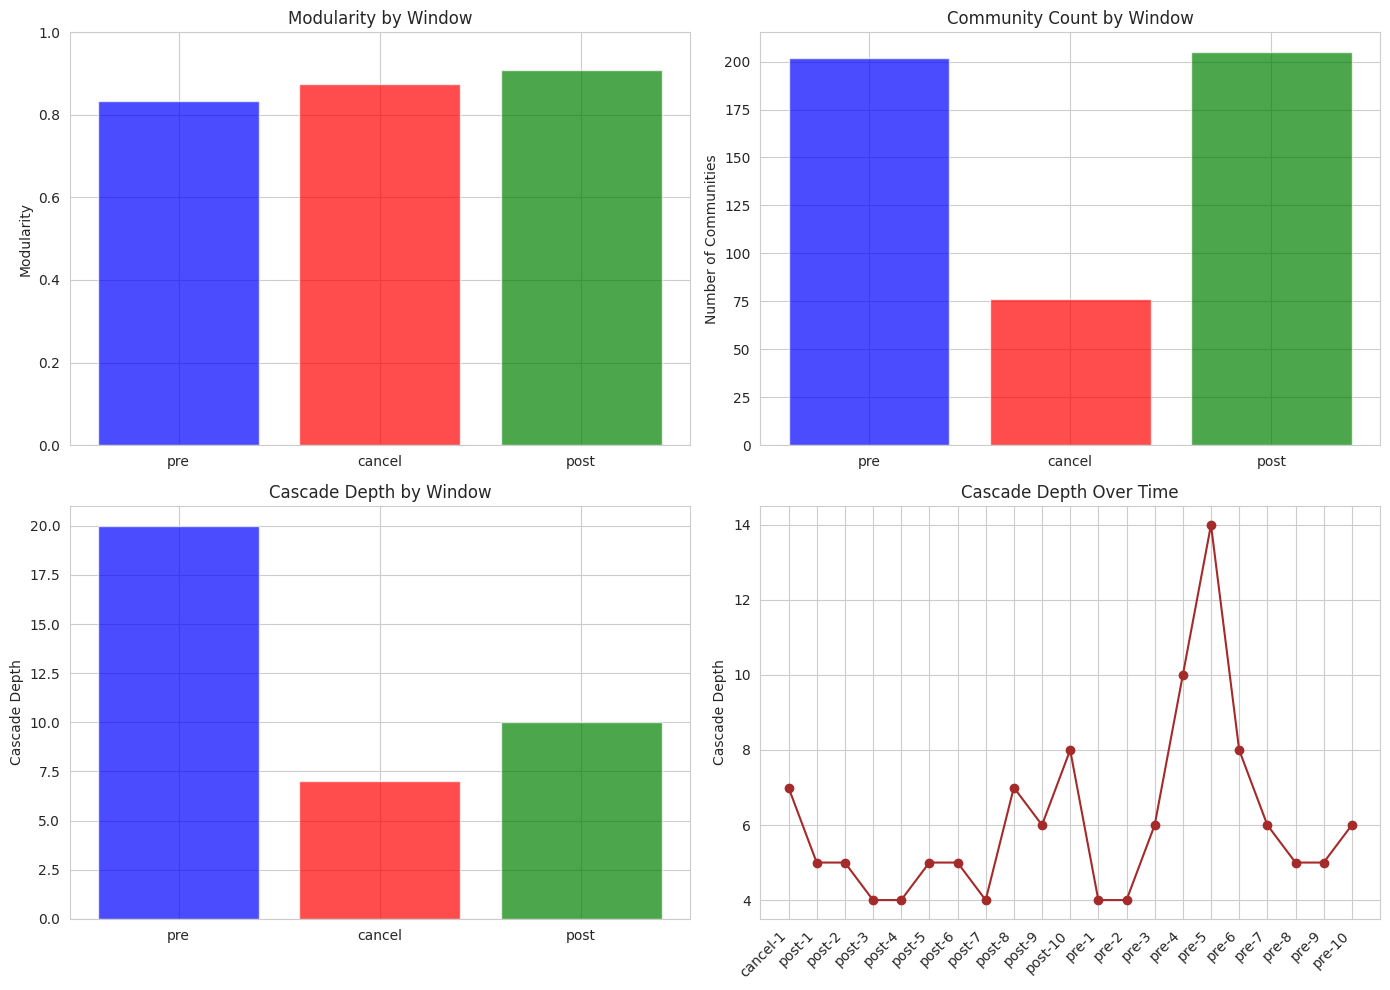

Saved: /home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis/03-analysis/figures/mimiminu_community_cascade.png

=== Community & Cascade Metrics Interpretation ===
Modularity: 0=random, 1=fully separated communities
Pre modularity: 0.8333
Cancel modularity: 0.8738
Post modularity: 0.9099

Pre cascade depth: 20.0
Cancel cascade depth: 7.0
Post cascade depth: 10.0


In [11]:
print("\n=== Community & Cascade Metrics by Window ===")
print(window_df[['num_communities', 'modularity', 'cascade_depth']])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

windows = ['pre', 'cancel', 'post']
colors = {'pre': 'blue', 'cancel': 'red', 'post': 'green'}

modularity_vals = [window_df.loc[w, 'modularity'] for w in windows]
axes[0, 0].bar(windows, modularity_vals, color=[colors[w] for w in windows], alpha=0.7)
axes[0, 0].set_ylabel('Modularity')
axes[0, 0].set_title('Modularity by Window')
axes[0, 0].set_ylim(0, 1)

communities_vals = [window_df.loc[w, 'num_communities'] for w in windows]
axes[0, 1].bar(windows, communities_vals, color=[colors[w] for w in windows], alpha=0.7)
axes[0, 1].set_ylabel('Number of Communities')
axes[0, 1].set_title('Community Count by Window')

cascade_vals = [window_df.loc[w, 'cascade_depth'] for w in windows]
axes[1, 0].bar(windows, cascade_vals, color=[colors[w] for w in windows], alpha=0.7)
axes[1, 0].set_ylabel('Cascade Depth')
axes[1, 0].set_title('Cascade Depth by Window')

cascade_over_time = [slot_df.loc[s, 'cascade_depth'] if s in slot_df.index else 0 for s in slot_order]
axes[1, 1].plot(x_pos, cascade_over_time, marker='o', color='brown')
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(x_labels, rotation=45, ha='right')
axes[1, 1].set_ylabel('Cascade Depth')
axes[1, 1].set_title('Cascade Depth Over Time')

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, f'{PERSON}_community_cascade.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURE_DIR}/{PERSON}_community_cascade.png")

print("\n=== Community & Cascade Metrics Interpretation ===")
print(f"Modularity: 0=random, 1=fully separated communities")
print(f"Pre modularity: {pre_metrics['modularity']:.4f}")
print(f"Cancel modularity: {cancel_metrics['modularity']:.4f}")
print(f"Post modularity: {post_metrics['modularity']:.4f}")
print(f"\nPre cascade depth: {pre_metrics['cascade_depth']}")
print(f"Cancel cascade depth: {cancel_metrics['cascade_depth']}")
print(f"Post cascade depth: {post_metrics['cascade_depth']}")

## 6) Export
- Network metrics tables to CSV
- Structure analysis with amplification ratios
- Summary statistics
- Key findings

In [12]:
person_output_dir = os.path.join(OUTPUT_DIR, PERSON)
os.makedirs(person_output_dir, exist_ok=True)

full_metrics_df = pd.DataFrame([full_metrics]).set_index('name')
full_metrics_df.to_csv(os.path.join(person_output_dir, 'network_full.csv'))
print(f"Saved: {person_output_dir}/network_full.csv")

window_df.to_csv(os.path.join(person_output_dir, 'network_by_window.csv'))
print(f"Saved: {person_output_dir}/network_by_window.csv")

slot_df.to_csv(os.path.join(person_output_dir, 'network_by_slot.csv'))
print(f"Saved: {person_output_dir}/network_by_slot.csv")

structure_analysis = pd.DataFrame({
    'metric': ['edge_amplification', 'density_amplification', 'node_amplification', 'gini_amplification',
               'pre_modularity', 'cancel_modularity', 'post_modularity',
               'pre_cascade_depth', 'cancel_cascade_depth', 'post_cascade_depth',
               'pre_num_communities', 'cancel_num_communities', 'post_num_communities'],
    'value': [edge_amplification, density_amplification, node_amplification, gini_amplification,
              pre_metrics['modularity'], cancel_metrics['modularity'], post_metrics['modularity'],
              pre_metrics['cascade_depth'], cancel_metrics['cascade_depth'], post_metrics['cascade_depth'],
              pre_metrics['num_communities'], cancel_metrics['num_communities'], post_metrics['num_communities']]
})
structure_analysis.to_csv(os.path.join(person_output_dir, 'network_structure_analysis.csv'), index=False)
print(f"Saved: {person_output_dir}/network_structure_analysis.csv")

if G_full.number_of_nodes() > 0:
    in_deg = dict(G_full.in_degree())
    out_deg = dict(G_full.out_degree())
    pagerank = nx.pagerank(G_full)
    betweenness = nx.betweenness_centrality(G_full)
    
    node_metrics = pd.DataFrame({
        'node': list(G_full.nodes()),
        'in_degree': [in_deg.get(n, 0) for n in G_full.nodes()],
        'out_degree': [out_deg.get(n, 0) for n in G_full.nodes()],
        'pagerank': [pagerank.get(n, 0) for n in G_full.nodes()],
        'betweenness': [betweenness.get(n, 0) for n in G_full.nodes()]
    })
    node_metrics = node_metrics.sort_values('pagerank', ascending=False)
    node_metrics.to_csv(os.path.join(person_output_dir, 'node_metrics.csv'), index=False)
    print(f"Saved: {person_output_dir}/node_metrics.csv")

print("\n" + "="*50)
print("=== Summary ===")
print(f"Person: {PERSON}")
print(f"Node type: {NODE_TYPE}")
print(f"Full graph: {G_full.number_of_nodes()} nodes, {G_full.number_of_edges()} edges")
print(f"Density: {nx.density(G_full):.6f}")
print(f"Connected components: {nx.number_connected_components(G_full.to_undirected())}")
print("\n--- Amplification (Cancel vs Pre) ---")
print(f"Edge ratio: {edge_amplification:.3f}")
print(f"Density ratio: {density_amplification:.3f}")
print("\n--- Polarization ---")
print(f"Pre Gini: {pre_metrics['degree_gini']:.4f}")
print(f"Cancel Gini: {cancel_metrics['degree_gini']:.4f}")
print(f"Post Gini: {post_metrics['degree_gini']:.4f}")
print("\n--- Community Structure ---")
print(f"Pre modularity: {pre_metrics['modularity']:.4f}")
print(f"Cancel modularity: {cancel_metrics['modularity']:.4f}")
print(f"Post modularity: {post_metrics['modularity']:.4f}")
print("\n--- Cascade Depth ---")
print(f"Pre: {pre_metrics['cascade_depth']}, Cancel: {cancel_metrics['cascade_depth']}, Post: {post_metrics['cascade_depth']}")

Saved: /home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis/03-analysis/outputs/mimiminu/network_full.csv
Saved: /home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis/03-analysis/outputs/mimiminu/network_by_window.csv
Saved: /home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis/03-analysis/outputs/mimiminu/network_by_slot.csv
Saved: /home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis/03-analysis/outputs/mimiminu/network_structure_analysis.csv


Saved: /home/mbchavez/Coding/Research/cancel-culture-sentiment-analysis/03-analysis/outputs/mimiminu/node_metrics.csv

=== Summary ===
Person: mimiminu
Node type: author
Full graph: 5345 nodes, 6780 edges
Density: 0.000237
Connected components: 317

--- Amplification (Cancel vs Pre) ---
Edge ratio: 0.192
Density ratio: 3.633

--- Polarization ---
Pre Gini: 0.7972
Cancel Gini: 0.8073
Post Gini: 0.8087

--- Community Structure ---
Pre modularity: 0.8333
Cancel modularity: 0.8738
Post modularity: 0.9099

--- Cascade Depth ---
Pre: 20.0, Cancel: 7.0, Post: 10.0
